# Imports

In [1]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski

### Load the file that will be the dataframe

In [2]:
df = pd.read_csv('acetylcholinesterase_03_bioactivity_data_curated.csv')

## Calculate Lipinski descriptors
The Lipinski descriptors are a collection of rule-of-thumb made to evaluate **druglikeness** of compounds, which are based on the ADME (Absorbption, Distribution, Metabolism and Excretion) characteristics that profile the pharmacokinetics of a drug. 

Lipinski analyzed all orally active FDA-approved drugs in order to develop the **Rule-of-Five** / **Lipinski's Rule**

The Lipinski's Rule states these four parameters:
* Molecular Weight < 500 Dalton;
* Octanol-water partition coefficient (logP) < 5
* Hydrogen bond donors < 5
* Hydrogen bond acceptors < 10


### Calculate Descriptors

In [3]:
# def a function lipinski
def lipinski(smiles, verbose=False): #Usa como input os smiles
    
    moldata = []
    for elem in smiles:
        if pd.isna(elem) or not isinstance(elem, str):
            continue
        mol = Chem.MolFromSmiles(elem)
        moldata.append(mol)

    baseData= np.arange(1,1)
    i=0
    for mol in moldata:
        
        desc_MolWt = Descriptors.MolWt(mol)
        desc_MolLogP = Descriptors.MolLogP(mol)
        desc_NumHDonors = Lipinski.NumHDonors(mol)
        desc_NumHAcceptors = Lipinski.NumHAcceptors(mol)

        row = np.array([desc_MolWt,
                        desc_MolLogP,
                        desc_NumHDonors,
                        desc_NumHAcceptors])
            
        if(i==0):
            baseData = row
        else:
            baseData = np.vstack([baseData, row])
        i=i+1

    columnNames=["MW","LogP","NumHDonors","NumHAcceptors"]
    descriptors = pd.DataFrame(data=baseData, columns=columnNames)

    return descriptors


In [4]:
type(df.canonical_smiles)

pandas.Series

In [5]:
df_lipinski = lipinski(df.canonical_smiles)
df_lipinski

,MW,LogP,NumHDonors,NumHAcceptors
0,312.325,2.80320,0.0,5.0
1,376.913,4.55460,0.0,4.0
2,426.851,5.35740,0.0,4.0
3,404.845,4.70690,0.0,4.0
4,346.334,3.09530,0.0,5.0
...,...,...,...,...
7170,449.295,7.04910,0.0,2.0
7171,356.816,2.94110,3.0,5.0
7172,414.465,3.03242,3.0,6.0
7173,415.324,4.65730,2.0,4.0


## Combine the df dataFrame from the previous notebook with the lipinski newly dataFrame

In [6]:
df_combined = pd.concat([df, df_lipinski], axis=1)
df_combined

,molecule_chembl_id,canonical_smiles,standard_value,bioactivity_class,MW,LogP,NumHDonors,NumHAcceptors
0,CHEMBL133897,CCOc1nn(-c2cccc(OCc3ccccc3)c2)c(=O)o1,750.00,active,312.325,2.80320,0.0,5.0
1,CHEMBL336398,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC1CC1,100.00,active,376.913,4.55460,0.0,4.0
2,CHEMBL131588,CN(C(=O)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F)c1ccccc1,50000.00,inactive,426.851,5.35740,0.0,4.0
3,CHEMBL130628,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F,300.00,active,404.845,4.70690,0.0,4.0
4,CHEMBL130478,CSc1nc(-c2ccc(OC(F)(F)F)cc2)nn1C(=O)N(C)C,800.00,active,346.334,3.09530,0.0,5.0
...,...,...,...,...,...,...,...,...
7170,CHEMBL6190210,FC(F)(F)c1cccc(-c2cc(-c3cccs3)n(-c3ccc(Br)cc3)...,0.48,active,449.295,7.04910,0.0,2.0
7171,CHEMBL6192902,O=C(NNC(=S)Nc1ccccc1[N+](=O)[O-])c1sccc1Cl,400.00,active,356.816,2.94110,3.0,5.0
7172,CHEMBL6191782,Cc1cc(=O)[nH]c2c1C(=O)C(NCNc1c3c(nc4ccccc14)CC...,11.10,active,414.465,3.03242,3.0,6.0
7173,CHEMBL6190113,O=C(NCCCNc1c2c(nc3ccccc13)CCC2)c1cnc(Cl)c(Cl)c1,52.00,active,415.324,4.65730,2.0,4.0


## Convert IC50 to pIC50
Once we have the IC50 Data, it is good to convert it to the negativa logarithmic scale -**log10(IC50)**, in order to have the data more uniformly distributed.

This custom function pIC50() will accept a DataFrame as input and then it will perform the following:

* Take the IC50 values from the _standard_value_ column and convert it from nM to M by multiplying the value by 10(-9)
* Take the molar value and apply -log10
* Delete the standard_value column and create a new pIC50 column



In [7]:
def pIC50(input):
    pIC50 = []

    for i in input['standard_value_norm']:
        molar = i*(10**-9)  #convert nM to M
        pIC50.append(-np.log10(molar))
        
    input['pIC50'] = pIC50
    x = input.drop('standard_value_norm', axis=1)

    return x


In [8]:
df_combined.standard_value.describe()

count    7.175000e+03
mean     1.225867e+05
std      2.131348e+06
min      0.000000e+00
25%      1.587450e+02
50%      2.410000e+03
75%      1.644000e+04
max      1.636817e+08
Name: standard_value, dtype: float64

In [9]:
-np.log10((10**-9) * 100000000)

np.float64(1.0)

**Obs:** Values greater than 100.000.000 need to be capped at 100.000.000, otherwise the negative logarithmic value will become negative. 

In order to do that we'll make a new function:

In [10]:
def norm_value(input):
    norm = []

    for i in input['standard_value']:
        if i > 100000000:
            i = 100000000
        norm.append(i)

    input['standard_value_norm'] = norm
    x = input.drop('standard_value', axis=1)

    return x

In [11]:
#We will apply the norm_value() function so that the values in the standard_value column is normalized:
df_norm = norm_value(df_combined)
df_norm

,molecule_chembl_id,canonical_smiles,bioactivity_class,MW,LogP,NumHDonors,NumHAcceptors,standard_value_norm
0,CHEMBL133897,CCOc1nn(-c2cccc(OCc3ccccc3)c2)c(=O)o1,active,312.325,2.80320,0.0,5.0,750.00
1,CHEMBL336398,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC1CC1,active,376.913,4.55460,0.0,4.0,100.00
2,CHEMBL131588,CN(C(=O)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F)c1ccccc1,inactive,426.851,5.35740,0.0,4.0,50000.00
3,CHEMBL130628,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F,active,404.845,4.70690,0.0,4.0,300.00
4,CHEMBL130478,CSc1nc(-c2ccc(OC(F)(F)F)cc2)nn1C(=O)N(C)C,active,346.334,3.09530,0.0,5.0,800.00
...,...,...,...,...,...,...,...,...
7170,CHEMBL6190210,FC(F)(F)c1cccc(-c2cc(-c3cccs3)n(-c3ccc(Br)cc3)...,active,449.295,7.04910,0.0,2.0,0.48
7171,CHEMBL6192902,O=C(NNC(=S)Nc1ccccc1[N+](=O)[O-])c1sccc1Cl,active,356.816,2.94110,3.0,5.0,400.00
7172,CHEMBL6191782,Cc1cc(=O)[nH]c2c1C(=O)C(NCNc1c3c(nc4ccccc14)CC...,active,414.465,3.03242,3.0,6.0,11.10
7173,CHEMBL6190113,O=C(NCCCNc1c2c(nc3ccccc13)CCC2)c1cnc(Cl)c(Cl)c1,active,415.324,4.65730,2.0,4.0,52.00


In [12]:
df_final = pIC50(df_norm)
df_final

/tmp/ipykernel_95/2548970326.py:6: RuntimeWarning: divide by zero encountered in log10
  pIC50.append(-np.log10(molar))


,molecule_chembl_id,canonical_smiles,bioactivity_class,MW,LogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL133897,CCOc1nn(-c2cccc(OCc3ccccc3)c2)c(=O)o1,active,312.325,2.80320,0.0,5.0,6.124939
1,CHEMBL336398,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC1CC1,active,376.913,4.55460,0.0,4.0,7.000000
2,CHEMBL131588,CN(C(=O)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F)c1ccccc1,inactive,426.851,5.35740,0.0,4.0,4.301030
3,CHEMBL130628,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F,active,404.845,4.70690,0.0,4.0,6.522879
4,CHEMBL130478,CSc1nc(-c2ccc(OC(F)(F)F)cc2)nn1C(=O)N(C)C,active,346.334,3.09530,0.0,5.0,6.096910
...,...,...,...,...,...,...,...,...
7170,CHEMBL6190210,FC(F)(F)c1cccc(-c2cc(-c3cccs3)n(-c3ccc(Br)cc3)...,active,449.295,7.04910,0.0,2.0,9.318759
7171,CHEMBL6192902,O=C(NNC(=S)Nc1ccccc1[N+](=O)[O-])c1sccc1Cl,active,356.816,2.94110,3.0,5.0,6.397940
7172,CHEMBL6191782,Cc1cc(=O)[nH]c2c1C(=O)C(NCNc1c3c(nc4ccccc14)CC...,active,414.465,3.03242,3.0,6.0,7.954677
7173,CHEMBL6190113,O=C(NCCCNc1c2c(nc3ccccc13)CCC2)c1cnc(Cl)c(Cl)c1,active,415.324,4.65730,2.0,4.0,7.283997


In [13]:
df_norm.standard_value_norm.describe()

count    7.175000e+03
mean     1.137112e+05
std      1.484625e+06
min      0.000000e+00
25%      1.587450e+02
50%      2.410000e+03
75%      1.644000e+04
max      1.000000e+08
Name: standard_value_norm, dtype: float64

#### Save file after pIC50 convertion

In [36]:
df_final.to_csv('acetylcholinesterase_04_bioactivity_data_3class_pIC50.csv')

## Removing the 'intermediate' bioactivity class

In [16]:
df_clean = df_final.dropna()
df_2class = df_clean[df_clean.bioactivity_class != 'intermediate']
df_2class

,molecule_chembl_id,canonical_smiles,bioactivity_class,MW,LogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL133897,CCOc1nn(-c2cccc(OCc3ccccc3)c2)c(=O)o1,active,312.325,2.80320,0.0,5.0,6.124939
1,CHEMBL336398,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC1CC1,active,376.913,4.55460,0.0,4.0,7.000000
2,CHEMBL131588,CN(C(=O)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F)c1ccccc1,inactive,426.851,5.35740,0.0,4.0,4.301030
3,CHEMBL130628,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F,active,404.845,4.70690,0.0,4.0,6.522879
4,CHEMBL130478,CSc1nc(-c2ccc(OC(F)(F)F)cc2)nn1C(=O)N(C)C,active,346.334,3.09530,0.0,5.0,6.096910
...,...,...,...,...,...,...,...,...
7170,CHEMBL6190210,FC(F)(F)c1cccc(-c2cc(-c3cccs3)n(-c3ccc(Br)cc3)...,active,449.295,7.04910,0.0,2.0,9.318759
7171,CHEMBL6192902,O=C(NNC(=S)Nc1ccccc1[N+](=O)[O-])c1sccc1Cl,active,356.816,2.94110,3.0,5.0,6.397940
7172,CHEMBL6191782,Cc1cc(=O)[nH]c2c1C(=O)C(NCNc1c3c(nc4ccccc14)CC...,active,414.465,3.03242,3.0,6.0,7.954677
7173,CHEMBL6190113,O=C(NCCCNc1c2c(nc3ccccc13)CCC2)c1cnc(Cl)c(Cl)c1,active,415.324,4.65730,2.0,4.0,7.283997


#### Save file without "intermediate value"

In [35]:
df_2class.to_csv('acetylcholinesterase_05_bioactivity_data_2class_pIC50.csv')

## Exploratory Data Analysis (Chemical Space Analysis) using Lipinski descriptors


In [20]:
#import library
import seaborn as sns
sns.set(style='ticks')
import matplotlib.pyplot as plt

### Frequency plot of the 2 bioactivity classes

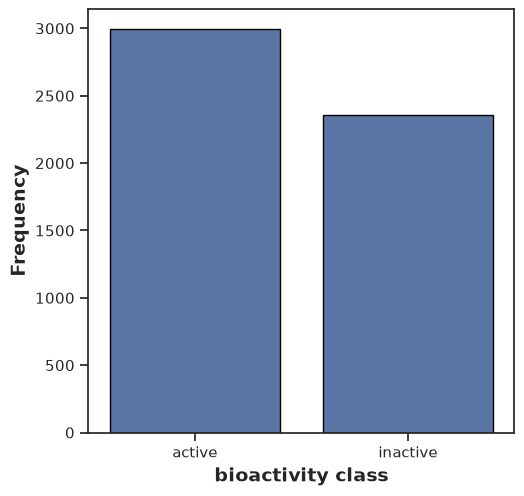

In [21]:
plt.figure(figsize=(5.5, 5.5))

sns.countplot(x='bioactivity_class', data=df_2class, edgecolor='black')

plt.xlabel('bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('Frequency', fontsize=14, fontweight='bold')

plt.savefig('plot_bioactivity_class.pdf')

### Scatter plot of MW versus logP

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.scatterplot(x='MW', y='LogP', data=df_2class, hue='bioactivity_class', size='pIC50', edgecolor='black', alpha=0.7)

plt.xlabel('MW', fontsize=14, fontweight='bold')
plt.ylabel('LogP', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0)
plt.savefig('plot_MW_vs_LogP.pdf')

The scatterplot shows the 2 bioactivity classes spanning similar chemical spaces 

## Box Plots

### pIC50 value

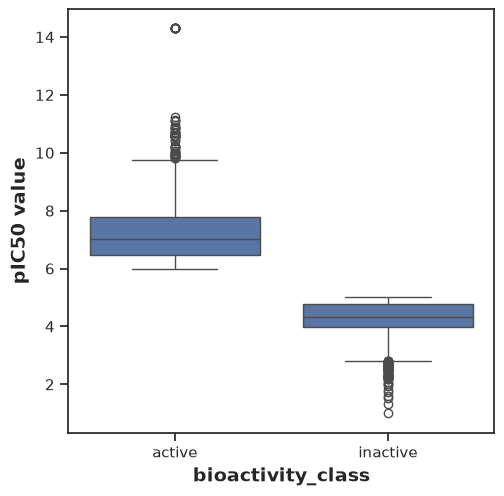

In [23]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'pIC50', data = df_2class)

plt.xlabel('bioactivity_class', fontsize= 14, fontweight='bold')
plt.ylabel('pIC50 value', fontsize=14, fontweight='bold')

plt.savefig('plot_ic50.pdf')


### Statistical analysis | Mann-Whitney U Test
The Mann-Whitney U Test allow us to see the the statistical significance of the difference between the two bioactivity classes (active and inactive)

In [24]:
 def mannwhitney(descriptor, verbose=False):
     from numpy.random import seed
     from numpy.random import randn
     from scipy.stats import mannwhitneyu
     
     seed(1) #seed the random number generator

     #Actives and inactives selection:
     selection = [descriptor, 'bioactivity_class']
     df = df_2class[selection]
     active = df[df.bioactivity_class == 'active']
     active = active[descriptor]

     selection = [descriptor, 'bioactivity_class']
     df = df_2class[selection]
     inactive = df[df.bioactivity_class == 'inactive']
     inactive = inactive[descriptor]

     stat, p = mannwhitneyu(active, inactive)#compare samples

     #interpret
     alpha= 0.05
     if p > alpha:
         interpretation = 'Same distribution (fail to reject H0)'
     else:
         interpretation = 'Different distribution (reject H0)'
         
     results = pd.DataFrame({'Descriptor':descriptor,
                            'Statistics':stat,
                            'p':p,
                            'alpha': alpha,
                            'interpretation':interpretation}, index=[0])
     filename = 'mannwhitneyu_' + descriptor + '.csv'
     results.to_csv(filename)

     return results

In [25]:
mannwhitney('pIC50')

,Descriptor,Statistics,p,alpha,interpretation
0,pIC50,7056858.0,0.0,0.05,Different distribution (reject H0)


### Perform the statistical analysis in all the other Lipinski parameters

### MW

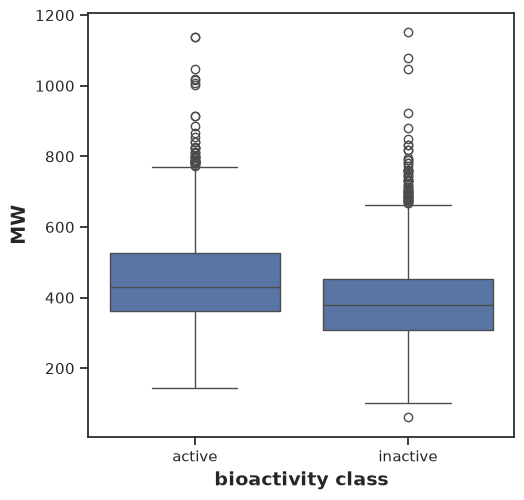

In [26]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x='bioactivity_class', y = 'MW', data = df_2class)

plt.xlabel('bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('MW', fontsize=14, fontweight='bold')

plt.savefig('plot_MW.pdf')

In [27]:
mannwhitney('MW')

,Descriptor,Statistics,p,alpha,interpretation
0,MW,4506711.5,4.263836e-68,0.05,Different distribution (reject H0)


### LogP

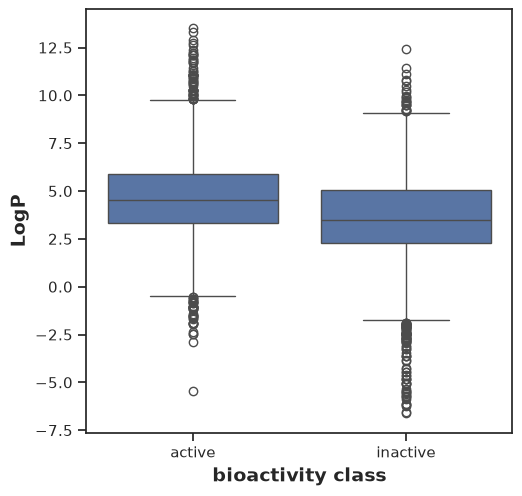

In [28]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x='bioactivity_class', y ='LogP', data=df_2class)

plt.xlabel('bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('LogP', fontsize=14, fontweight='bold')

plt.savefig('plot_LogP.pdf')

In [29]:
mannwhitney('LogP')

,Descriptor,Statistics,p,alpha,interpretation
0,LogP,4484703.0,3.776872e-65,0.05,Different distribution (reject H0)


### NumHDonors

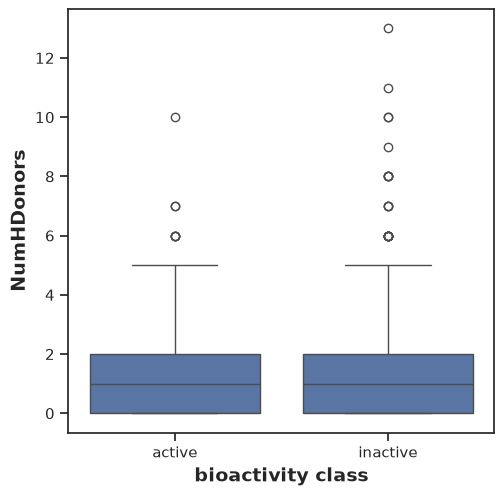

In [30]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x='bioactivity_class', y='NumHDonors', data = df_2class)

plt.xlabel('bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHDonors', fontsize=14, fontweight='bold')

plt.savefig('plot_NumHDonors.pdf')

In [31]:
mannwhitney('NumHDonors')

,Descriptor,Statistics,p,alpha,interpretation
0,NumHDonors,3930724.0,6.115131e-14,0.05,Different distribution (reject H0)


### NumHAcceptors

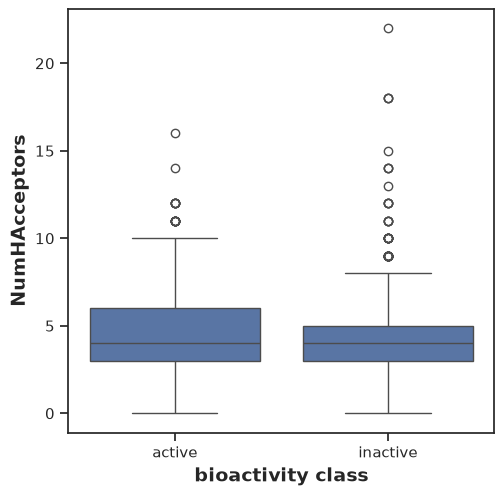

In [32]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x='bioactivity_class', y='NumHAcceptors', data = df_2class)

plt.xlabel('bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHAcceptors', fontsize=14, fontweight='bold')

plt.savefig('plot_NumHAcceptors.pdf')

In [33]:
mannwhitney('NumHAcceptors')

,Descriptor,Statistics,p,alpha,interpretation
0,NumHAcceptors,3818333.5,1.522751e-07,0.05,Different distribution (reject H0)


### Zip Files